# Piloto LLM: Sentimiento Financiero Dirigido al Ticker (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`)

Tras comprobar en `finbert_pilot_v3_regex_unificada.ipynb` que los modelos *zero-shot* locales tocan techo en **~62.7% (`FinBERT`)** y **~70.7% (`FinBERT + DeBERTa-ABSA`)**, mientras que un LLM dirigido al ticker alcanza **~78.7% (`F2 = 0.805`)**, este notebook se dedica en exclusiva a optimizar y dimensionar la vía **LLM** para producción sobre las **27.350 noticias relevantes de Silver**.

### Qué experimentos realiza este notebook
1. **Benchmark Multi-Proveedor (`12` modelos calidad/precio):**
   - **Google Gemini (`GEMINI_API_KEY`):** `gemini-2.5-flash` (caché), `gemini-3.1-flash-lite` (`500 RPD` gratis), `gemini-3.5-flash-lite` (`500 RPD` gratis, `$0.30/$2.50`).
   - **OpenAI / ChatGPT (`OPENAI_API_KEY`):** `gpt-5-nano` (`$0.05/$0.40`), `gpt-4o-mini` (`$0.15/$0.60`), `gpt-5-mini` (`$0.25/$2.00`), `gpt-4.1-mini` (`$0.40/$1.60`).
   - **Anthropic / Claude (`ANTHROPIC_API_KEY`):** `claude-haiku-5-5` (`$0.10/$0.50`), `claude-haiku-4-5-20251001` (`$1.00/$5.00`), `claude-sonnet-4-6` (`$3.00/$15.00`).
   - **xAI / Grok (`XAI_API_KEY`):** `grok-4.20-0309-non-reasoning` (`$1.25/$2.50`), `grok-4.3` (`$1.25/$2.50`).
2. **Prompt Engineering (`Prompt v1` vs `Prompt v2 Few-Shot`):** añade ejemplos concretos de neutros ambiguos (opinión de analista, previas de resultados, mandatos IPO/M&A) para elevar el `Recall Neutral` por encima del `66.7%`.
3. **Optimización de Contexto y Tamaño de Lote (`batch_size`):**
   - `RE_ADAPTATIVA` vs `RE_TIT_GATE` vs `Artículo Completo (2.500 chars)` para medir si [`base_nlp.py`](../../articulos/models/base_nlp.py) logra la misma precisión gastando ~75% menos tokens.
   - `batch_size = 10` vs `15` vs `25` noticias por llamada para minimizar llamadas `RPD` sin degradar calidad.
4. **Consistencia Multi-Ticker + Calculadora de Producción (`27.350` noticias):** proyección real con tokens medidos (`usage_metadata`) de días gratis y coste total en USD.

## 1. Configuración, Credenciales (`.env`) y Catálogo de Costes/Límites

In [22]:
import asyncio, importlib, json, os, re, sys, time, urllib.error, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from google import genai
from google.genai import types

curr = Path.cwd()
PROJ_ROOT = next((p for p in [curr, *curr.parents] if (p / "pyproject.toml").exists()), curr)
for p in (PROJ_ROOT / "src", PROJ_ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import config.settings as _settings_mod
importlib.reload(_settings_mod)
import articulos.models.base_nlp as _base_nlp_mod
importlib.reload(_base_nlp_mod)

from config.settings import settings
from dependencies.dependencies import get_compactor, get_storage_repository
from articulos.models.base_nlp import BaseProcesadorArticulo

def _clean_env(val: str) -> str:
    return (val or "").split("//")[0].split("#")[0].strip()

GEMINI_API_KEY = _clean_env(settings.gemini_api_key or os.getenv("GEMINI_API_KEY", ""))
OPENAI_API_KEY = _clean_env(settings.openai_api_key or os.getenv("OPENAI_API_KEY", ""))
ANTHROPIC_API_KEY = _clean_env(settings.anthropic_api_key or os.getenv("ANTHROPIC_API_KEY", ""))
XAI_API_KEY = _clean_env(settings.xai_api_key or os.getenv("XAI_API_KEY", ""))

NOMBRE_CANONICO = {
    "JPM": "JPMorgan Chase",
    "BAC": "Bank of America",
    "WFC": "Wells Fargo",
    "C": "Citigroup",
    "GS": "Goldman Sachs",
    "MS": "Morgan Stanley",
}

# Catálogo oficial de límites gratuitos (0 = solo Tier Pago), precios estándar (USD por 1M tokens) y soporte de temperature
CATALOGO_MODELOS = {
    "gemini-2.5-flash":             {"prov": "gemini",    "rpm": 5,   "tpm": 250_000, "rpd": 20,     "in_usd_1m": 0.30, "out_usd_1m": 2.50,  "pause_s": 13.0, "es_gemma": False, "send_temp": True},
    "gemini-3.1-flash-lite":        {"prov": "gemini",    "rpm": 15,  "tpm": 250_000, "rpd": 500,    "in_usd_1m": 0.25, "out_usd_1m": 1.50,  "pause_s": 4.5,  "es_gemma": False, "send_temp": True},
    "gemini-3.5-flash-lite":        {"prov": "gemini",    "rpm": 15,  "tpm": 250_000, "rpd": 500,    "in_usd_1m": 0.30, "out_usd_1m": 2.50,  "pause_s": 4.5,  "es_gemma": False, "send_temp": True},
    "gemma-4-26b-a4b-it":           {"prov": "gemini",    "rpm": 30,  "tpm": 16_000,  "rpd": 14_400, "in_usd_1m": 0.00, "out_usd_1m": 0.00,  "pause_s": 20.0, "es_gemma": True,  "send_temp": True},
    "gemma-4-31b-it":               {"prov": "gemini",    "rpm": 30,  "tpm": 16_000,  "rpd": 14_400, "in_usd_1m": 0.00, "out_usd_1m": 0.00,  "pause_s": 20.0, "es_gemma": True,  "send_temp": True},
    "gpt-5-nano":                   {"prov": "openai",    "rpm": 500, "tpm": 200_000, "rpd": 0,      "in_usd_1m": 0.05, "out_usd_1m": 0.40,  "pause_s": 0.4,  "es_gemma": False, "send_temp": False},
    "gpt-4o-mini":                  {"prov": "openai",    "rpm": 500, "tpm": 200_000, "rpd": 0,      "in_usd_1m": 0.15, "out_usd_1m": 0.60,  "pause_s": 0.4,  "es_gemma": False, "send_temp": True},
    "gpt-5-mini":                   {"prov": "openai",    "rpm": 500, "tpm": 200_000, "rpd": 0,      "in_usd_1m": 0.25, "out_usd_1m": 2.00,  "pause_s": 0.4,  "es_gemma": False, "send_temp": False},
    "gpt-4.1-mini":                 {"prov": "openai",    "rpm": 500, "tpm": 200_000, "rpd": 0,      "in_usd_1m": 0.40, "out_usd_1m": 1.60,  "pause_s": 0.4,  "es_gemma": False, "send_temp": True},
    "claude-haiku-5-5":             {"prov": "anthropic", "rpm": 50,  "tpm": 50_000,  "rpd": 0,      "in_usd_1m": 0.10, "out_usd_1m": 0.50,  "pause_s": 1.2,  "es_gemma": False, "send_temp": False},
    "claude-haiku-4-5-20251001":    {"prov": "anthropic", "rpm": 50,  "tpm": 50_000,  "rpd": 0,      "in_usd_1m": 1.00, "out_usd_1m": 5.00,  "pause_s": 1.2,  "es_gemma": False, "send_temp": True},
    "claude-sonnet-4-6":            {"prov": "anthropic", "rpm": 50,  "tpm": 30_000,  "rpd": 0,      "in_usd_1m": 3.00, "out_usd_1m": 15.00, "pause_s": 1.5,  "es_gemma": False, "send_temp": False},
    "grok-4.20-0309-non-reasoning": {"prov": "xai",       "rpm": 60,  "tpm": 250_000, "rpd": 0,      "in_usd_1m": 1.25, "out_usd_1m": 2.50,  "pause_s": 0.8,  "es_gemma": False, "send_temp": True},
    "grok-4.3":                     {"prov": "xai",       "rpm": 60,  "tpm": 250_000, "rpd": 0,      "in_usd_1m": 1.25, "out_usd_1m": 2.50,  "pause_s": 0.8,  "es_gemma": False, "send_temp": True},
    "grok-4.7":                     {"prov": "xai",       "rpm": 60,  "tpm": 250_000, "rpd": 0,      "in_usd_1m": 2.00, "out_usd_1m": 6.00,  "pause_s": 1.0,  "es_gemma": False, "send_temp": True},
}

print(f"[OK] PROJ_ROOT: {PROJ_ROOT}")
print(f"[OK] Gemini: {'SÍ' if GEMINI_API_KEY else 'NO'} | OpenAI (ChatGPT): {'SÍ' if OPENAI_API_KEY else 'NO'} | Anthropic (Claude): {'SÍ' if ANTHROPIC_API_KEY else 'NO'} | xAI (Grok): {'SÍ' if XAI_API_KEY else 'NO'}")

[OK] PROJ_ROOT: c:\proyectos\TFM-Master
[OK] Gemini: SÍ | OpenAI (ChatGPT): SÍ | Anthropic (Claude): SÍ | xAI (Grok): SÍ


## 2. Carga de la Muestra Alineada (`150` Noticias), Ground Truth y Caché Unificada

In [23]:
CSV_GT = PROJ_ROOT / "scratch" / "finbert_pilot_v3_revision_manual.csv"
CACHE_V3 = PROJ_ROOT / "scratch" / "gemini_pilot_v3_cache.csv"
CACHE_LLM = PROJ_ROOT / "scratch" / "llm_sentiment_pilot_cache.csv"

async def cargar_muestra_gt(key="processed/huggingface/categorized_checkpoint.parquet"):
    local_ckpt = PROJ_ROOT / "data" / "silver_categorized_checkpoint.parquet"
    local_backup = PROJ_ROOT / "data" / "processed_multisource_bancos_2010_2023.parquet"
    compact = get_compactor()
    if local_ckpt.exists():
        df = pd.DataFrame(compact.decompact(local_ckpt.read_bytes()))
    else:
        repo = get_storage_repository()
        try:
            try:
                df = pd.DataFrame(compact.decompact(await repo.get(key)))
            except Exception:
                raw = local_backup.read_bytes() if local_backup.exists() else await repo.get("processed/huggingface/multisource_bancos_2010_2023.parquet")
                df = pd.DataFrame(compact.decompact(raw))
        finally:
            await repo.close()
    if "article" not in df.columns and "process_text" in df.columns:
        df["article"] = df["process_text"]

    gt = pd.read_csv(CSV_GT)
    lkp = df.drop_duplicates(subset=["ticker", "title"]).set_index(["ticker", "title"])
    aligned = []
    for _, r in gt.iterrows():
        k = (r["ticker"], r["titular"])
        row_d = lkp.loc[k].to_dict()
        row_d["ticker"], row_d["title"] = k
        aligned.append(row_d)
    return pd.DataFrame(aligned).reset_index(drop=True), gt

df_silver, df_gt = await cargar_muestra_gt()
y_true = df_gt["etiqueta_manual"].astype(int).to_numpy()

# Migrar filas válidas previas de gemini_pilot_v3_cache.csv para no repetir llamadas
if not CACHE_LLM.exists() and CACHE_V3.exists():
    df_prev = pd.read_csv(CACHE_V3)
    df_prev = df_prev[df_prev["motivo"] != "error"].copy()
    if not df_prev.empty:
        df_prev["exp_id"] = df_prev["model"] + "|v1|RE_ADAPTATIVA|b15"
        df_prev["in_tokens"] = np.nan
        df_prev["out_tokens"] = np.nan
        df_prev["lat_ms"] = np.nan
        df_prev.to_csv(CACHE_LLM, index=False, encoding="utf-8-sig")
        print(f"[OK] Importadas {len(df_prev)} evaluaciones válidas desde {CACHE_V3.name}")

print(f"[OK] Muestra lista: {len(df_silver)} artículos | Distribución GT: {pd.Series(y_true).value_counts().sort_index().to_dict()}")

 INFO     | 2026-11-21 14:06:17.191750 | ParquetCompactor | Descompactados 89,846 registros desde buffer Parquet (42,799,560 bytes).
[OK] Muestra lista: 150 artículos | Distribución GT: {-1: 26, 0: 78, 1: 46}


## 3. Motor Unificado de Prompts, Inferencia por Lotes con Caché y Métricas

Definimos dos *System Prompts* para comparar en el Experimento 2:
* **`PROMPT_V1`**: el mismo prompt directo que logró `78.7%` con `gemini-2.5-flash`.
* **`PROMPT_V2_FEWSHOT`**: añade reglas explícitas y **4 ejemplos *few-shot*** para frenar los falsos positivos/negativos en noticias neutras (opinión de analista, previas, mandatos IPO/M&A y comparativas).

In [24]:
class SentimientoItem(BaseModel):
    idx: int = Field(description="Índice numérico de la noticia dentro del lote")
    label: int = Field(description="Polaridad exclusiva para el banco objetivo: 1 (Positivo), 0 (Neutral), -1 (Negativo)")
    sentiment_score: float = Field(description="Puntuación continua entre -1.0 (muy negativo) y +1.0 (muy positivo)")
    p_pos: float = Field(default=0.0, description="Probabilidad positiva [0.0, 1.0]")
    p_neg: float = Field(default=0.0, description="Probabilidad negativa [0.0, 1.0]")
    p_neu: float = Field(default=0.0, description="Probabilidad neutral [0.0, 1.0]")
    motivo: str = Field(default="ok", description="Justificación breve en español (máx 12 palabras)")

class LoteSentimientoLLM(BaseModel):
    resultados: list[SentimientoItem]

PROMPT_V1 = """Eres un analista financiero cuantitativo experto en los 6 grandes bancos de EE. UU. (JPMorgan Chase, Bank of America, Wells Fargo, Citigroup, Goldman Sachs, Morgan Stanley).
Para cada noticia del lote, evalúa EXCLUSIVAMENTE el impacto bursátil/fundamental sobre el BANCO OBJETIVO indicado:
- +1 (Positivo): Beneficios o ingresos que baten estimaciones, subidas bursátiles del banco, aumento de dividendo/recompra, mejora de recomendación hacia el banco.
- -1 (Negativo): Pérdidas, caída bursátil del banco, recortes de plantilla, multas regulatorias, demandas, provisiones por mora, rebaja de previsión del banco.
- 0 (Neutral): Calendarios o previas de resultados ('scheduled to report'), mandatos rutinarios de M&A o IPO ('hired as underwriter/advisor'), opinión del banco actuando como analista sobre terceros/macro/bonos/divisas, o noticias sobre competidores sin impacto directo en el banco objetivo.

Ignora por completo el sentimiento de otros bancos competidores mencionados en el texto. Devuelve exactamente un elemento en `resultados` por cada `idx` del lote, manteniendo el `idx` exacto."""

PROMPT_V2_FEWSHOT = PROMPT_V1 + """

REGLA ESTRICTA DE NEUTRALIDAD (ante duda entre hecho material y simple mención informativa, elige 0):
- Si la noticia solo informa de fechas próximas de resultados ("set to report", "Earnings Preview", "scheduled to release"), dividendos rutinarios sin subida, yields de preferentes, opciones disponibles o múltiplos P/B -> SIEMPRE 0.
- Si el banco solo aparece como asesor/colocador de una IPO o venta ("lead underwriter", "hired to prepare sale", "serving as financial advisor") -> SIEMPRE 0.
- Si un estratega/analista del banco opina sobre macro, Fed, inflación, Bitcoin o bonos extranjeros -> SIEMPRE 0.

EJEMPLOS DE REFERENCIA:
1) BANCO: Citigroup (C) | "Muted Investment Banking to Hurt BofA's Q1... Citigroup is scheduled to report on Apr 13." -> label=0 (el impacto negativo es de BofA; para Citigroup es solo fecha).
2) BANCO: Goldman Sachs (GS) | "Bitcoin Retreats As Goldman CEO Raises Doubts" -> label=0 (opinión sobre Bitcoin, no deterioro de resultados de GS).
3) BANCO: Morgan Stanley (MS) | "Carrefour hires Morgan Stanley to run $1.9B sale" -> label=0 (mandato rutinario de asesoría M&A).
4) BANCO: Wells Fargo (WFC) | "Financial ETFs Down... Wells Fargo Q4 EPS 67c beat 63c estimate" -> label=+1 (WFC batió estimaciones pese al titular bajista sectorial)."""

PROMPTS = {"v1": PROMPT_V1, "v2_fewshot": PROMPT_V2_FEWSHOT}

def _load_cache_df() -> pd.DataFrame:
    if CACHE_LLM.exists():
        return pd.read_csv(CACHE_LLM)
    return pd.DataFrame(columns=["exp_id", "model", "ticker", "titular", "label", "sentiment", "P_pos", "P_neg", "P_neu", "motivo", "in_tokens", "out_tokens", "lat_ms"])

_JSON_INSTR = (
    "\nResponde ÚNICAMENTE con un objeto JSON válido (sin markdown) con la clave 'resultados', una lista de objetos con EXACTAMENTE estos campos y tipos:"
    "\n- idx (int): índice numérico [idx=...] de la noticia"
    "\n- label (int): SOLO 1 (Positivo), 0 (Neutral) o -1 (Negativo) — NUNCA texto ni nombre de banco"
    "\n- sentiment_score (float entre -1.0 y 1.0)"
    "\n- p_pos (float 0..1), p_neg (float 0..1), p_neu (float 0..1)"
    "\n- motivo (str): justificación breve en español (máx 12 palabras)"
    '\nEjemplo: {"resultados": [{"idx": 0, "label": 1, "sentiment_score": 0.75, "p_pos": 0.85, "p_neg": 0.05, "p_neu": 0.10, "motivo": "Supera estimaciones de beneficio"}]}'
)

def _post_json(url: str, headers: dict, payload_dict: dict) -> dict:
    req = urllib.request.Request(
        url,
        data=json.dumps(payload_dict).encode("utf-8"),
        headers={"Content-Type": "application/json", **headers},
        method="POST",
    )
    try:
        with urllib.request.urlopen(req, timeout=180) as r:
            return json.loads(r.read().decode("utf-8"))
    except urllib.error.HTTPError as exc:
        body = exc.read().decode("utf-8", errors="ignore")[:300]
        raise RuntimeError(f"HTTP {exc.code}: {body}") from exc

def _call_openai_compat_sync(url: str, api_key: str, model_name: str, sys_prompt: str, user_prompt: str, send_temp: bool = True) -> tuple[str, int, int]:
    payload = {
        "model": model_name,
        "response_format": {"type": "json_object"},
        "messages": [
            {"role": "system", "content": sys_prompt + _JSON_INSTR},
            {"role": "user", "content": user_prompt},
        ],
    }
    if send_temp:
        payload["temperature"] = 0.0
    if model_name.startswith("gpt-5"):
        payload["reasoning_effort"] = "low"
    data = _post_json(url, {"Authorization": f"Bearer {api_key}"}, payload)
    u = data.get("usage", {})
    return data["choices"][0]["message"]["content"], int(u.get("prompt_tokens", 0)), int(u.get("completion_tokens", 0))

def _call_anthropic_sync(api_key: str, model_name: str, sys_prompt: str, user_prompt: str, send_temp: bool = True) -> tuple[str, int, int]:
    payload = {
        "model": model_name,
        "max_tokens": 8192,
        "system": sys_prompt + _JSON_INSTR,
        "messages": [{"role": "user", "content": user_prompt}],
    }
    if send_temp:
        payload["temperature"] = 0.0
    data = _post_json("https://api.anthropic.com/v1/messages", {"x-api-key": api_key, "anthropic-version": "2023-06-01"}, payload)
    u = data.get("usage", {})
    txt = "\n".join(b["text"] for b in data.get("content", []) if isinstance(b, dict) and b.get("type") == "text" and "text" in b)
    if not txt:
        raise RuntimeError(f"Anthropic sin bloque text: {[b.get('type') for b in data.get('content', [])]}")
    return txt, int(u.get("input_tokens", 0)), int(u.get("output_tokens", 0))

_FATAL_ERR_TOKENS = ("HTTP 400", "HTTP 401", "HTTP 402", "HTTP 403", "HTTP 404", "404 NOT_FOUND", "400 INVALID_ARGUMENT", "no longer available", "credit_balance", "insufficient_quota", "model_not_found", "invalid_api_key")

async def ejecutar_experimento_llm(
    df_in: pd.DataFrame,
    contextos: list[str],
    model_name: str,
    prompt_key: str = "v1",
    ctx_name: str = "RE_ADAPTATIVA",
    batch_size: int = 15,
    pause_s: float | None = None,
    max_chars_ctx: int = 1000,
) -> pd.DataFrame:
    exp_id = f"{model_name}|{prompt_key}|{ctx_name}|b{batch_size}"
    df_cache = _load_cache_df()
    done = df_cache[(df_cache["exp_id"] == exp_id) & (df_cache["motivo"] != "error")]
    cache_map = {(r["ticker"], r["titular"]): r.to_dict() for _, r in done.iterrows()}

    pend = [(i, r.ticker, r.title, contextos[i]) for i, r in enumerate(df_in.itertuples()) if (r.ticker, r.title) not in cache_map]
    print(f"[{exp_id}] En caché: {len(df_in)-len(pend)} | Pendientes: {len(pend)} ({(len(pend)+batch_size-1)//batch_size} llamadas)", flush=True)

    if pend:
        meta = CATALOGO_MODELOS.get(model_name, {"prov": "gemini", "pause_s": 5.0, "es_gemma": "gemma" in model_name.lower(), "send_temp": True})
        prov = meta.get("prov", "gemini")
        p_wait = meta["pause_s"] if pause_s is None else pause_s
        es_gemma = meta["es_gemma"]
        send_temp = meta.get("send_temp", True)
        sys_prompt = PROMPTS[prompt_key]
        client = genai.Client(api_key=GEMINI_API_KEY, http_options=types.HttpOptions(api_version="v1beta")) if prov == "gemini" else None
        abort_model = False

        for start in range(0, len(pend), batch_size):
            if abort_model:
                break
            lote = pend[start:start + batch_size]
            bloques = [f"[idx={idx}] BANCO: {NOMBRE_CANONICO.get(tk, tk)} ({tk}) | TITULAR: {tit} | CONTEXTO: {ctx[:max_chars_ctx]}" for idx, tk, tit, ctx in lote]
            prompt = "Evalúa las siguientes noticias:\n\n" + "\n\n".join(bloques)
            if es_gemma:
                prompt = sys_prompt + "\n\nResponde ÚNICAMENTE con JSON válido con clave 'resultados' (lista de: idx, label, sentiment_score, p_pos, p_neg, p_neu, motivo).\n\n" + prompt

            t0 = time.perf_counter()
            ok = False
            for intento in range(4):
                try:
                    if prov == "gemini":
                        cfg = (
                            types.GenerateContentConfig(temperature=0.0)
                            if es_gemma
                            else types.GenerateContentConfig(
                                system_instruction=sys_prompt,
                                response_mime_type="application/json",
                                response_schema=LoteSentimientoLLM,
                                temperature=0.0,
                            )
                        )
                        resp = await client.aio.models.generate_content(model=model_name, contents=prompt, config=cfg)
                        raw = resp.text.strip()
                        usage = getattr(resp, "usage_metadata", None)
                        tot_in = getattr(usage, "prompt_token_count", 0) or 0
                        tot_out = getattr(usage, "candidates_token_count", 0) or 0
                    elif prov == "openai":
                        raw, tot_in, tot_out = await asyncio.to_thread(_call_openai_compat_sync, "https://api.openai.com/v1/chat/completions", OPENAI_API_KEY, model_name, sys_prompt, prompt, send_temp)
                    elif prov == "xai":
                        raw, tot_in, tot_out = await asyncio.to_thread(_call_openai_compat_sync, "https://api.x.ai/v1/chat/completions", XAI_API_KEY, model_name, sys_prompt, prompt, send_temp)
                    elif prov == "anthropic":
                        raw, tot_in, tot_out = await asyncio.to_thread(_call_anthropic_sync, ANTHROPIC_API_KEY, model_name, sys_prompt, prompt, send_temp)
                    else:
                        raise ValueError(f"Proveedor desconocido: {prov}")

                    dt_ms = (time.perf_counter() - t0) * 1000.0
                    m = re.search(r"\{.*\}", raw, re.DOTALL)
                    parsed = LoteSentimientoLLM.model_validate_json(m.group(0) if m else raw)
                    in_tok = tot_in / max(len(lote), 1)
                    out_tok = tot_out / max(len(lote), 1)

                    por_idx = {it.idx: it for it in parsed.resultados}
                    for idx, tk, tit, _ in lote:
                        it = por_idx.get(idx)
                        if it is not None:
                            cache_map[(tk, tit)] = {
                                "exp_id": exp_id, "model": model_name, "ticker": tk, "titular": tit,
                                "label": int(np.clip(it.label, -1, 1)),
                                "sentiment": float(np.clip(it.sentiment_score, -1.0, 1.0)),
                                "P_pos": float(np.clip(it.p_pos, 0.0, 1.0)),
                                "P_neg": float(np.clip(it.p_neg, 0.0, 1.0)),
                                "P_neu": float(np.clip(it.p_neu, 0.0, 1.0)),
                                "motivo": it.motivo,
                                "in_tokens": round(float(in_tok), 1),
                                "out_tokens": round(float(out_tok), 1),
                                "lat_ms": round(dt_ms / max(len(lote), 1), 1),
                            }
                    ok = True
                    print(f"  Lote {start//batch_size + 1}/{(len(pend)+batch_size-1)//batch_size} OK ({len(por_idx)}/{len(lote)}) | {in_tok:.0f}+{out_tok:.0f} tok/doc", flush=True)
                    break
                except Exception as exc:
                    msg = str(exc)
                    if any(tok in msg for tok in _FATAL_ERR_TOKENS):
                        print(f"  [ABORT] {model_name} error fatal: {msg}", flush=True)
                        abort_model = True
                        break
                    wait = (2 ** intento) * 10
                    print(f"  [WARN] Lote {start//batch_size + 1} intento {intento+1}: {msg} -> {wait}s", flush=True)
                    await asyncio.sleep(wait)
                    if "503" in msg and intento >= 1:
                        break
            if abort_model:
                break
            if not ok:
                for _, tk, tit, _ in lote:
                    cache_map.setdefault((tk, tit), {"exp_id": exp_id, "model": model_name, "ticker": tk, "titular": tit, "label": 0, "sentiment": 0.0, "P_pos": 0.0, "P_neg": 0.0, "P_neu": 1.0, "motivo": "error", "in_tokens": np.nan, "out_tokens": np.nan, "lat_ms": np.nan})

            df_other = _load_cache_df()
            df_other = df_other[(df_other["exp_id"] != exp_id) & (df_other["motivo"] != "error")]
            df_cur = pd.DataFrame([v for v in cache_map.values() if v.get("motivo") != "error"])
            pd.concat([df_other, df_cur], ignore_index=True).to_csv(CACHE_LLM, index=False, encoding="utf-8-sig")
            if start + batch_size < len(pend):
                await asyncio.sleep(p_wait)

    return pd.DataFrame([cache_map.get((r.ticker, r.title), {"exp_id": exp_id, "model": model_name, "ticker": r.ticker, "titular": r.title, "label": 0, "sentiment": 0.0, "P_pos": 0.0, "P_neg": 0.0, "P_neu": 1.0, "motivo": "sin_respuesta", "in_tokens": np.nan, "out_tokens": np.nan, "lat_ms": np.nan}) for r in df_in.itertuples()])

def calcular_kpis(y_true_arr, df_pred: pd.DataFrame, nombre: str) -> dict:
    valid_mask = ~df_pred["motivo"].astype(str).isin(["error", "sin_respuesta"])
    if int(valid_mask.sum()) == 0:
        return {"Experimento": nombre, "N": 0, "Accuracy": np.nan, "Precision": np.nan, "Recall": np.nan, "F1-Score": np.nan, "F2(β=2)": np.nan, "Rec+1": np.nan, "Rec0": np.nan, "Rec-1": np.nan, "Inv": 0, "InTok/doc": np.nan, "OutTok/doc": np.nan}
    yt = y_true_arr[valid_mask]
    yp = df_pred.loc[valid_mask, "label"].astype(int).to_numpy()
    acc = float((yt == yp).mean())
    precs, recs, f1s, f2s = {}, {}, {}, {}
    for c in (-1, 0, 1):
        tp = int(((yt == c) & (yp == c)).sum())
        fp = int(((yt != c) & (yp == c)).sum())
        fn = int(((yt == c) & (yp != c)).sum())
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
        f2 = 5 * p * r / (4 * p + r) if (4 * p + r) > 0 else 0.0
        precs[c], recs[c], f1s[c], f2s[c] = p, r, f1, f2
    return {
        "Experimento": nombre,
        "N": int(valid_mask.sum()),
        "Accuracy": round(acc, 3),
        "Precision": round(float(np.mean(list(precs.values()))), 3),
        "Recall": round(float(np.mean(list(recs.values()))), 3),
        "F1-Score": round(float(np.mean(list(f1s.values()))), 3),
        "F2(β=2)": round(float(np.mean(list(f2s.values()))), 3),
        "Rec+1": round(recs[1], 3),
        "Rec0": round(recs[0], 3),
        "Rec-1": round(recs[-1], 3),
        "Inv": int((((yt == 1) & (yp == -1)) | ((yt == -1) & (yp == 1))).sum()),
        "InTok/doc": round(float(df_pred["in_tokens"].mean()), 1) if df_pred["in_tokens"].notna().any() else np.nan,
        "OutTok/doc": round(float(df_pred["out_tokens"].mean()), 1) if df_pred["out_tokens"].notna().any() else np.nan,
    }

## 4. Experimento 1 — Benchmark Multi-Proveedor (`12` Modelos, `N = 150`)

Comparamos las opciones calidad/precio de las 4 principales APIs usando el mismo contexto (`RE_ADAPTATIVA` + `PROMPT_V1`, `batch_size=15`):
* **Gemini (`GEMINI_API_KEY`):** `gemini-2.5-flash` *(caché)*, `gemini-3.1-flash-lite` (`500 RPD` gratis) y `gemini-3.5-flash-lite` (`500 RPD` gratis).
* **OpenAI / ChatGPT (`OPENAI_API_KEY`):** `gpt-5-nano` (`$0.05/$0.40`), `gpt-4o-mini` (`$0.15/$0.60`), `gpt-5-mini` (`$0.25/$2.00`) y `gpt-4.1-mini` (`$0.40/$1.60`).
* **Anthropic / Claude (`ANTHROPIC_API_KEY`):** `claude-haiku-5-5` (`$0.10/$0.50`), `claude-haiku-4-5-20251001` (`$1.00/$5.00`) y `claude-sonnet-4-6` (`$3.00/$15.00`).
* **xAI / Grok (`XAI_API_KEY`):** `grok-4.20-0309-non-reasoning` (`$1.25/$2.50`) y `grok-4.3` (`$1.25/$2.50`).

*Coste estimado total de correr los `12` modelos sobre `N = 150` artículos: **< $0.50 en total** entre todos los proveedores.*

In [25]:
ctx_adapt = [BaseProcesadorArticulo.extraer_contexto_banco(r.title, r.article, r.ticker, titular_condicional=True, ventana_auto_multiticker=True)[0] for r in df_silver.itertuples()]

resultados_exp = {}
if GEMINI_API_KEY:
    for m_name in ["gemini-2.5-flash", "gemini-3.1-flash-lite", "gemini-3.5-flash-lite"]:
        resultados_exp[m_name] = await ejecutar_experimento_llm(df_silver, ctx_adapt, model_name=m_name, prompt_key="v1", ctx_name="RE_ADAPTATIVA", batch_size=15)

if OPENAI_API_KEY:
    for o_name in ["gpt-5-nano", "gpt-4o-mini", "gpt-5-mini", "gpt-4.1-mini"]:
        resultados_exp[o_name] = await ejecutar_experimento_llm(df_silver, ctx_adapt, model_name=o_name, prompt_key="v1", ctx_name="RE_ADAPTATIVA", batch_size=15)

if ANTHROPIC_API_KEY:
    for c_name in ["claude-haiku-5-5", "claude-haiku-4-5-20251001", "claude-sonnet-4-6"]:
        resultados_exp[c_name] = await ejecutar_experimento_llm(df_silver, ctx_adapt, model_name=c_name, prompt_key="v1", ctx_name="RE_ADAPTATIVA", batch_size=15)

if XAI_API_KEY:
    for x_name in ["grok-4.20-0309-non-reasoning", "grok-4.3"]:
        resultados_exp[x_name] = await ejecutar_experimento_llm(df_silver, ctx_adapt, model_name=x_name, prompt_key="v1", ctx_name="RE_ADAPTATIVA", batch_size=15)

if resultados_exp:
    tabla_exp1 = pd.DataFrame([calcular_kpis(y_true, df_r, nom) for nom, df_r in resultados_exp.items()])
    display(tabla_exp1.sort_values("Accuracy", ascending=False))
else:
    print("[INFO] Añade GEMINI_API_KEY, OPENAI_API_KEY, ANTHROPIC_API_KEY o XAI_API_KEY en .env para ejecutar el benchmark.")

[gemini-2.5-flash|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[gemini-3.1-flash-lite|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[gemini-3.5-flash-lite|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[gpt-5-nano|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[gpt-4o-mini|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[gpt-5-mini|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[gpt-4.1-mini|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[claude-haiku-5-5|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[claude-haiku-4-5-20251001|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[claude-sonnet-4-6|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[grok-4.20-0309-non-reasoning|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)
[grok-4.3|v1|RE_ADAPTATIVA|b15] En caché: 150 | Pendientes: 0 (0 llamadas)


,Experimento,N,Accuracy,Precision,Recall,F1-Score,F2(β=2),Rec+1,Rec0,Rec-1,Inv,InTok/doc,OutTok/doc
7,claude-haiku-5-5,150,0.893,0.887,0.897,0.892,0.895,0.870,0.897,0.923,2,315.3,171.3
11,grok-4.3,150,0.867,0.851,0.868,0.859,0.864,0.848,0.872,0.885,4,196.3,61.5
6,gpt-4.1-mini,150,0.847,0.864,0.837,0.847,0.840,0.717,0.910,0.885,0,183.7,63.7
2,gemini-3.5-flash-lite,150,0.840,0.848,0.825,0.834,0.828,0.848,0.859,0.769,3,178.9,91.9
9,claude-sonnet-4-6,150,0.840,0.820,0.860,0.834,0.848,0.848,0.808,0.923,1,215.6,92.3
5,gpt-5-mini,150,0.827,0.806,0.842,0.820,0.832,0.848,0.795,0.885,4,183.6,96.6
1,gemini-3.1-flash-lite,150,0.813,0.794,0.825,0.806,0.817,0.783,0.808,0.885,3,NaN,NaN
0,gemini-2.5-flash,150,0.787,0.777,0.829,0.781,0.805,0.935,0.667,0.885,5,NaN,NaN
3,gpt-5-nano,150,0.787,0.781,0.776,0.778,0.777,0.739,0.821,0.769,2,172.0,393.5
10,grok-4.20-0309-non-reasoning,150,0.773,0.771,0.790,0.779,0.786,0.717,0.769,0.885,5,195.7,58.8


## 5. Experimento 2 — Prompt Engineering (`Prompt v1` vs `Prompt v2 Few-Shot`)

Probamos sobre el modelo ganador del Experimento 1 (`claude-haiku-5-5`, sin saturación `503`) si añadir reglas estrictas de neutralidad y 4 ejemplos *few-shot* (`PROMPT_V2_FEWSHOT`) supera el `89.3%` de `Prompt v1`.

In [27]:
MODELO_OPT = "claude-haiku-5-5"
if ANTHROPIC_API_KEY:
    resultados_exp[f"{MODELO_OPT} (v2_fewshot)"] = await ejecutar_experimento_llm(
        df_silver, ctx_adapt, model_name=MODELO_OPT, prompt_key="v2_fewshot", ctx_name="RE_ADAPTATIVA", batch_size=15
    )
    cmp_prompt = pd.DataFrame([
        calcular_kpis(y_true, resultados_exp[MODELO_OPT], f"{MODELO_OPT} | Prompt v1"),
        calcular_kpis(y_true, resultados_exp[f"{MODELO_OPT} (v2_fewshot)"], f"{MODELO_OPT} | Prompt v2 Few-Shot"),
    ])
    display(cmp_prompt)

[claude-haiku-5-5|v2_fewshot|RE_ADAPTATIVA|b15] En caché: 15 | Pendientes: 135 (9 llamadas)


  Lote 1/9 OK (15/15) | 363+175 tok/doc
  Lote 2/9 OK (15/15) | 401+152 tok/doc
  Lote 3/9 OK (15/15) | 329+199 tok/doc
  Lote 4/9 OK (15/15) | 330+155 tok/doc
  Lote 5/9 OK (15/15) | 347+164 tok/doc
  Lote 6/9 OK (15/15) | 323+156 tok/doc
  Lote 7/9 OK (15/15) | 365+177 tok/doc
  Lote 8/9 OK (15/15) | 380+174 tok/doc
  Lote 9/9 OK (15/15) | 357+175 tok/doc


,Experimento,N,Accuracy,Precision,Recall,F1-Score,F2(β=2),Rec+1,Rec0,Rec-1,Inv,InTok/doc,OutTok/doc
0,claude-haiku-5-5 | Prompt v1,150,0.893,0.887,0.897,0.892,0.895,0.870,0.897,0.923,2,315.3,171.3
1,claude-haiku-5-5 | Prompt v2 Few-Shot,150,0.853,0.886,0.813,0.839,0.821,0.696,0.974,0.769,2,356.8,171.8


## 6. Experimento 3 — Contexto de Entrada y Tamaño de Lote (`batch_size`)

Medimos sobre `claude-haiku-5-5`:
* **3A. Contexto (`N = 60`):** `RE_TIT_GATE` vs `RE_ADAPTATIVA` vs `Artículo Completo (2.500 chars)` para comprobar cuántos tokens ahorra [`base_nlp.py`](../../articulos/models/base_nlp.py) frente a enviar la noticia entera.
* **3B. Tamaño de lote (`N = 75`):** `batch_size = 10` vs `15` vs `25` para verificar si agrupar **25 noticias por llamada** conserva la precisión (reduciendo las peticiones a la API un 40%).

In [28]:
if ANTHROPIC_API_KEY:
    # 3A: Comparativa de contexto sobre 60 artículos
    sub60 = df_silver.head(60).reset_index(drop=True)
    y60 = y_true[:60]
    ctx_gate_60 = [BaseProcesadorArticulo.extraer_contexto_banco(r.title, r.article, r.ticker, ventana_frases=0, titular_condicional=True)[0] for r in sub60.itertuples()]
    ctx_full_60 = [str(r.article)[:2500] for r in sub60.itertuples()]

    df_c_gate = await ejecutar_experimento_llm(sub60, ctx_gate_60, MODELO_OPT, "v2_fewshot", "RE_TIT_GATE", batch_size=15, max_chars_ctx=1000)
    df_c_adap = resultados_exp[f"{MODELO_OPT} (v2_fewshot)"].iloc[:60].reset_index(drop=True)
    df_c_full = await ejecutar_experimento_llm(sub60, ctx_full_60, MODELO_OPT, "v2_fewshot", "ARTICULO_2500", batch_size=10, max_chars_ctx=2500)

    print("=== 3A. IMPACTO DEL CONTEXTO (N=60) ===")
    display(pd.DataFrame([
        calcular_kpis(y60, df_c_gate, "RE_TIT_GATE (base_nlp)"),
        calcular_kpis(y60, df_c_adap, "RE_ADAPTATIVA (base_nlp)"),
        calcular_kpis(y60, df_c_full, "ARTICULO_2500 (sin podar)"),
    ]))

    # 3B: Tamaño de lote (batch_size 10 vs 15 vs 25 sobre 75 artículos)
    sub75 = df_silver.head(75).reset_index(drop=True)
    y75 = y_true[:75]
    df_b10 = await ejecutar_experimento_llm(sub75, ctx_adapt[:75], MODELO_OPT, "v2_fewshot", "RE_ADAPTATIVA", batch_size=10)
    df_b15 = resultados_exp[f"{MODELO_OPT} (v2_fewshot)"].iloc[:75].reset_index(drop=True)
    df_b25 = await ejecutar_experimento_llm(sub75, ctx_adapt[:75], MODELO_OPT, "v2_fewshot", "RE_ADAPTATIVA", batch_size=25)

    print("=== 3B. IMPACTO DEL BATCH SIZE POR LLAMADA (N=75) ===")
    display(pd.DataFrame([
        calcular_kpis(y75, df_b10, "batch_size = 10"),
        calcular_kpis(y75, df_b15, "batch_size = 15"),
        calcular_kpis(y75, df_b25, "batch_size = 25"),
    ]))

[claude-haiku-5-5|v2_fewshot|RE_TIT_GATE|b15] En caché: 0 | Pendientes: 60 (4 llamadas)
  Lote 1/4 OK (15/15) | 352+206 tok/doc
  Lote 2/4 OK (15/15) | 360+186 tok/doc
  Lote 3/4 OK (15/15) | 388+148 tok/doc
  Lote 4/4 OK (15/15) | 318+195 tok/doc
[claude-haiku-5-5|v2_fewshot|ARTICULO_2500|b10] En caché: 0 | Pendientes: 60 (6 llamadas)
  Lote 1/6 OK (10/10) | 1087+198 tok/doc
  Lote 2/6 OK (10/10) | 1064+223 tok/doc
  Lote 3/6 OK (10/10) | 1058+168 tok/doc
  Lote 4/6 OK (10/10) | 1064+180 tok/doc
  Lote 5/6 OK (10/10) | 1135+235 tok/doc
  Lote 6/6 OK (10/10) | 1099+281 tok/doc
=== 3A. IMPACTO DEL CONTEXTO (N=60) ===


,Experimento,N,Accuracy,Precision,Recall,F1-Score,F2(β=2),Rec+1,Rec0,Rec-1,Inv,InTok/doc,OutTok/doc
0,RE_TIT_GATE (base_nlp),60,0.800,0.873,0.756,0.788,0.764,0.611,0.966,0.692,0,354.5,183.8
1,RE_ADAPTATIVA (base_nlp),60,0.817,0.860,0.775,0.802,0.782,0.667,0.966,0.692,1,366.9,179.3
2,ARTICULO_2500 (sin podar),60,0.750,0.852,0.694,0.728,0.699,0.500,0.966,0.615,0,1084.6,214.2


[claude-haiku-5-5|v2_fewshot|RE_ADAPTATIVA|b10] En caché: 0 | Pendientes: 75 (8 llamadas)
  Lote 1/8 OK (10/10) | 451+225 tok/doc
  Lote 2/8 OK (10/10) | 422+209 tok/doc
  Lote 3/8 OK (10/10) | 379+165 tok/doc
  Lote 4/8 OK (10/10) | 478+146 tok/doc
  Lote 5/8 OK (10/10) | 378+232 tok/doc
  Lote 6/8 OK (10/10) | 384+219 tok/doc
  Lote 7/8 OK (10/10) | 397+158 tok/doc
  Lote 8/8 OK (5/5) | 485+158 tok/doc
[claude-haiku-5-5|v2_fewshot|RE_ADAPTATIVA|b25] En caché: 0 | Pendientes: 75 (3 llamadas)
  Lote 1/3 OK (25/25) | 345+175 tok/doc
  Lote 2/3 OK (25/25) | 324+157 tok/doc
  Lote 3/3 OK (25/25) | 293+166 tok/doc
=== 3B. IMPACTO DEL BATCH SIZE POR LLAMADA (N=75) ===


,Experimento,N,Accuracy,Precision,Recall,F1-Score,F2(β=2),Rec+1,Rec0,Rec-1,Inv,InTok/doc,OutTok/doc
0,batch_size = 10,75,0.867,0.896,0.838,0.859,0.844,0.727,0.973,0.812,1,417.5,191.1
1,batch_size = 15,75,0.840,0.881,0.802,0.828,0.809,0.682,0.973,0.750,1,359.4,174.5
2,batch_size = 25,75,0.827,0.859,0.798,0.816,0.803,0.636,0.946,0.812,1,320.7,165.9


## 7. Experimento 4 — Consistencia Multi-Ticker y Calculadora de Producción (`27.350` Noticias)

1. Verificamos en artículos que mencionan **>= 2 bancos** que el LLM asigna notas distintas según el `ticker` objetivo.
2. Calculamos **días gratis en AI Studio** y **coste exacto en USD** para procesar las **27.350 noticias relevantes** usando los tokens medios reales medidos en el Experimento 1.

In [29]:
N_PROD = 27_350
BATCH_PROD = 25

# 4A. Test Multi-Ticker sobre 15 artículos con >=2 bancos (1-2 llamadas)
if ANTHROPIC_API_KEY:
    multi = df_silver[df_silver.apply(lambda r: BaseProcesadorArticulo.contar_bancos_mencionados(f"{r.title} {r.article}") >= 2, axis=1)].head(15)
    pares_mt = []
    for r in multi.itertuples():
        for tk in [k for k in NOMBRE_CANONICO if BaseProcesadorArticulo.menciona_banco(f"{r.title} {r.article}", k)]:
            c_txt, _ = BaseProcesadorArticulo.extraer_contexto_banco(r.title, r.article, tk, titular_condicional=True, ventana_auto_multiticker=True)
            pares_mt.append({"idx_art": r.Index, "ticker": tk, "title": r.title, "ctx": c_txt})
    df_mt_in = pd.DataFrame(pares_mt)
    df_mt_out = await ejecutar_experimento_llm(df_mt_in, df_mt_in["ctx"].tolist(), MODELO_OPT, "v2_fewshot", "MT_TEST", batch_size=25)
    df_mt_in["sentiment"] = df_mt_out["sentiment"].values
    disp = df_mt_in.groupby("idx_art")["sentiment"].agg(["count", lambda s: s.max() - s.min()]).rename(columns={"<lambda_0>": "rango"})
    print(f"[Multi-Ticker] Artículos: {len(disp)} | Rango medio entre bancos: {disp['rango'].mean():.3f} | % rango > 0.3: {100*(disp['rango']>0.3).mean():.1f}%")
    display(df_mt_in.pivot(index="idx_art", columns="ticker", values="sentiment").round(2).head(10))

# 4B. Calculadora de Costes y Cuota para 27.350 noticias (usando tokens reales medidos, o fallback ~210 in / ~45 out)
avg_in = 210.0
avg_out = 45.0
if "resultados_exp" in locals():
    for df_r in resultados_exp.values():
        if df_r["in_tokens"].notna().any():
            avg_in = float(df_r["in_tokens"].mean())
            avg_out = float(df_r["out_tokens"].mean())
            break

n_calls_25 = int(np.ceil(N_PROD / BATCH_PROD))

filas_coste = []
for m_nom, info in CATALOGO_MODELOS.items():
    m_in, m_out = avg_in, avg_out
    acc_medido = np.nan
    if "resultados_exp" in locals() and m_nom in resultados_exp:
        df_m = resultados_exp[m_nom]
        if df_m["in_tokens"].notna().any():
            m_in = float(df_m["in_tokens"].mean())
            m_out = float(df_m["out_tokens"].mean())
        acc_medido = calcular_kpis(y_true, df_m, m_nom)["Accuracy"]

    usd_std = ((N_PROD * m_in) / 1e6) * info["in_usd_1m"] + ((N_PROD * m_out) / 1e6) * info["out_usd_1m"]
    usd_batch = usd_std * 0.5  # Gemini, OpenAI y Anthropic aplican 50% descuento en Batch API
    dias_gratis = round(n_calls_25 / info["rpd"], 2) if info["rpd"] > 0 else "Solo pago"
    filas_coste.append({
        "Modelo": m_nom,
        "Proveedor": info["prov"].capitalize(),
        "Accuracy (N=150)": acc_medido,
        "In/Out tok": f"{m_in:.0f}/{m_out:.0f}",
        "RPD Gratis": info["rpd"],
        "Llamadas (batch=25)": n_calls_25,
        "Días en Free Tier": dias_gratis,
        "Coste Pago Std ($)": round(usd_std, 2),
        "Coste Batch API -50% ($)": round(usd_batch, 2),
    })

print(f"\n=== PROYECCIÓN PRODUCCIÓN ({N_PROD:,} noticias | fallback {avg_in:.0f} in + {avg_out:.0f} out tok/doc) ===")
display(pd.DataFrame(filas_coste).sort_values(["Coste Pago Std ($)"]))

[claude-haiku-5-5|v2_fewshot|MT_TEST|b25] En caché: 0 | Pendientes: 56 (3 llamadas)
  Lote 1/3 OK (25/25) | 229+139 tok/doc
  Lote 2/3 OK (25/25) | 208+158 tok/doc
  Lote 3/3 OK (6/6) | 501+307 tok/doc
[Multi-Ticker] Artículos: 15 | Rango medio entre bancos: 0.283 | % rango > 0.3: 40.0%


ticker,BAC,C,GS,JPM,MS,WFC
idx_art,,,,,,
3,0.6,NaN,NaN,NaN,NaN,0.7
4,NaN,0.0,NaN,0.0,NaN,0.0
6,-0.4,-0.3,NaN,NaN,-0.30,-0.3
8,0.8,-0.7,-0.85,0.8,0.75,0.7
11,-0.5,-0.5,-0.50,-0.5,-0.50,-0.5
12,0.0,0.0,0.00,0.0,0.00,NaN
13,0.0,NaN,NaN,-0.4,NaN,-0.4
14,NaN,NaN,0.00,0.0,0.00,NaN
16,0.0,NaN,-0.50,0.0,0.00,NaN



=== PROYECCIÓN PRODUCCIÓN (27,350 noticias | fallback 179 in + 92 out tok/doc) ===


,Modelo,Proveedor,Accuracy (N=150),In/Out tok,RPD Gratis,Llamadas (batch=25),Días en Free Tier,Coste Pago Std ($),Coste Batch API -50% ($)
3,gemma-4-26b-a4b-it,Gemini,NaN,179/92,14400,1094,0.08,0.00,0.00
4,gemma-4-31b-it,Gemini,NaN,179/92,14400,1094,0.08,0.00,0.00
6,gpt-4o-mini,Openai,0.753,184/76,0,1094,Solo pago,1.99,1.00
9,claude-haiku-5-5,Anthropic,0.893,315/171,0,1094,Solo pago,3.21,1.60
5,gpt-5-nano,Openai,0.787,172/394,0,1094,Solo pago,4.54,2.27
8,gpt-4.1-mini,Openai,0.847,184/64,0,1094,Solo pago,4.80,2.40
1,gemini-3.1-flash-lite,Gemini,0.813,179/92,500,1094,2.19,4.99,2.50
7,gpt-5-mini,Openai,0.827,184/97,0,1094,Solo pago,6.54,3.27
0,gemini-2.5-flash,Gemini,0.787,179/92,20,1094,54.7,7.75,3.88
2,gemini-3.5-flash-lite,Gemini,0.840,179/92,500,1094,2.19,7.75,3.88


## 8. Visualización Final: Precisión, Coste y Matriz de Confusión del Modelo Ganador

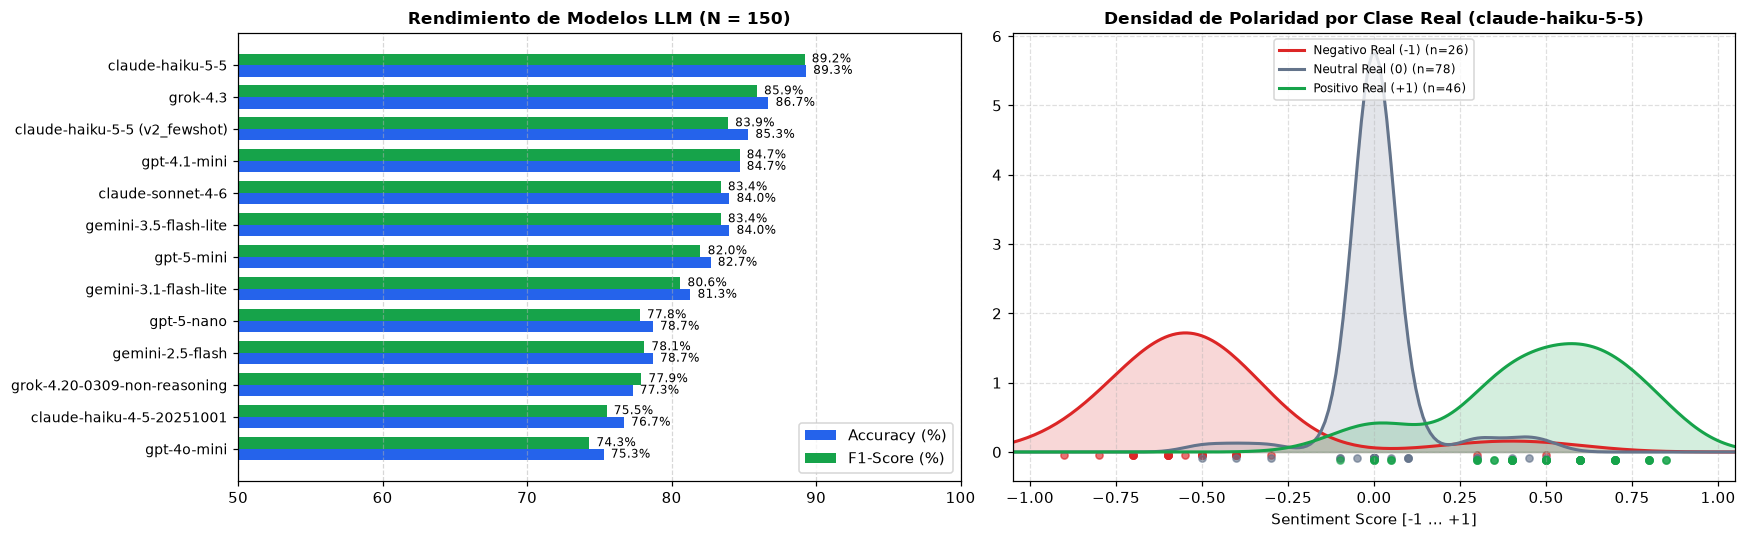

Matriz de confusión — claude-haiku-5-5:


Predicho,-1,0,1
Real,,,
-1,24,0,2
0,3,70,5
1,0,6,40


In [30]:
all_kpis = pd.DataFrame([calcular_kpis(y_true, df_r, nom) for nom, df_r in resultados_exp.items()]).dropna(subset=["Accuracy"]).sort_values("Accuracy", ascending=True) if ("resultados_exp" in locals() and resultados_exp) else pd.DataFrame()
if not all_kpis.empty:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), dpi=110)
    y_pos = np.arange(len(all_kpis))
    h = 0.36
    ax1.barh(y_pos - h/2, all_kpis["Accuracy"] * 100, h, label="Accuracy (%)", color="#2563eb")
    ax1.barh(y_pos + h/2, all_kpis["F1-Score"] * 100, h, label="F1-Score (%)", color="#16a34a")
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(all_kpis["Experimento"], fontsize=9)
    ax1.set_xlim(50, 100)
    ax1.set_title("Rendimiento de Modelos LLM (N = 150)", fontsize=11, fontweight="bold")
    ax1.legend(loc="lower right")
    ax1.grid(axis="x", linestyle="--", alpha=0.5)
    for i, (av, fv) in enumerate(zip(all_kpis["Accuracy"] * 100, all_kpis["F1-Score"] * 100)):
        ax1.text(av + 0.5, i - h/2, f"{av:.1f}%", va="center", fontsize=8)
        ax1.text(fv + 0.5, i + h/2, f"{fv:.1f}%", va="center", fontsize=8)

    best_nom = all_kpis.iloc[-1]["Experimento"]
    df_best = resultados_exp[best_nom]
    valid_m = ~df_best["motivo"].astype(str).isin(["error", "sin_respuesta"])
    mapa_lbl = {-1: ("Negativo Real (-1)", "#dc2626"), 0: ("Neutral Real (0)", "#64748b"), 1: ("Positivo Real (+1)", "#16a34a")}
    grid = np.linspace(-1.05, 1.05, 200)
    for val, (etiq, col) in mapa_lbl.items():
        sub = df_best.loc[valid_m & (y_true == val), "sentiment"].dropna().to_numpy(dtype=float)
        if len(sub) > 1 and sub.std() > 1e-6:
            bw = 1.06 * sub.std() * (len(sub) ** (-0.2))
            dens = np.exp(-0.5 * ((grid[:, None] - sub[None, :]) / bw) ** 2).mean(axis=1) / (bw * np.sqrt(2 * np.pi))
            ax2.fill_between(grid, dens, color=col, alpha=0.18)
            ax2.plot(grid, dens, color=col, linewidth=2, label=f"{etiq} (n={len(sub)})")
        ax2.scatter(sub, np.full(len(sub), -0.04 * (val + 2)), color=col, alpha=0.65, s=22)
    ax2.set_xlim(-1.05, 1.05)
    ax2.set_title(f"Densidad de Polaridad por Clase Real ({best_nom})", fontsize=11, fontweight="bold")
    ax2.set_xlabel("Sentiment Score [-1 ... +1]")
    ax2.legend(loc="upper center", fontsize=8)
    ax2.grid(True, linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

    print(f"Matriz de confusión — {best_nom}:")
    display(pd.crosstab(pd.Series(y_true[valid_m], name="Real"), pd.Series(df_best.loc[valid_m, "label"].astype(int).to_numpy(), name="Predicho")))

## 9. Prueba con distintos promt y variantes para ver como influye esto en el resultado

In [33]:
_JSON_INSTR = (
    "\nReturn ONLY a valid JSON object (no markdown) with key 'resultados', a list of objects with EXACT fields:"
    "\n- idx (int): exact [idx=...] from the prompt"
    "\n- label (int): ONLY 1 (Positive), 0 (Neutral), or -1 (Negative) — NEVER text or bank name"
    "\n- sentiment_score (float in [-1.0, 1.0])"
    "\n- p_pos (float 0..1), p_neg (float 0..1), p_neu (float 0..1)"
    "\n- motivo (str): brief rationale (max 10 words)"
    '\nExample: {"resultados": [{"idx": 0, "label": 1, "sentiment_score": 0.75, "p_pos": 0.85, "p_neg": 0.05, "p_neu": 0.10, "motivo": "Beat consensus EPS estimates"}]}'
)

PROMPT_V1_EN = """You are a senior quantitative financial analyst covering the US Big 6 banks (JPMorgan Chase, Bank of America, Wells Fargo, Citigroup, Goldman Sachs, Morgan Stanley).
For each news item in the batch, evaluate EXCLUSIVELY the equity/fundamental impact on the specified TARGET BANK:
- +1 (Positive): Earnings or revenue beating estimates, stock rallies for the target bank, dividend hikes/buybacks, analyst upgrades toward the bank.
- -1 (Negative): Earnings misses or losses, stock drops for the target bank, layoffs, regulatory fines, lawsuits, credit-loss provisions, guidance cuts.
- 0 (Neutral): Earnings calendars/previews ('scheduled to report'), routine M&A/IPO mandates ('hired as underwriter/advisor'), commentary by the bank's analysts on macro/rates/FX/third parties, or competitor news with no direct impact on the target bank.

Ignore sentiment toward competing banks mentioned in the same text. Return exactly one item in `resultados` per `idx` in the batch, preserving each exact `idx`."""

PROMPT_V2_EN_EQUITY = """You are a US banking equity analyst evaluating news impact strictly for the named TARGET BANK (JPM, BAC, WFC, C, GS, MS):
- +1 (Positive): Material positive catalyst or bullish fundamental/price signal for the target bank (beat estimates, raised guidance, buyback/dividend hike, analyst upgrade/stock pick, strong stress-test capital return, notable share gain).
- -1 (Negative): Material negative catalyst or bearish signal for the target bank (miss, weak revenue/NII outlook, dividend/bonus/job cut, fine/probe/lawsuit, notable share drop).
- 0 (Neutral): Purely informational or non-material mention (earnings date notice without outlook, routine underwriting/advisory mandate, macro/Fed/crypto commentary by bank strategists, or news driving a peer bank rather than the target bank).

Evaluate each target bank independently. Return one JSON item per exact `idx`."""

PROMPT_V3_EN_COMPACT = """Classify equity sentiment for the specified TARGET BANK ONLY (-1 Negative, 0 Neutral, +1 Positive):
+1: earnings/revenue beat, bullish outlook, dividend/buyback raise, analyst buy/upgrade, stock outperformance (+0.6..+1.0 strong, +0.2..+0.5 mild).
-1: miss, weak guidance, layoffs, fines/lawsuits, stock drop (-1.0..-0.6 strong, -0.5..-0.2 mild).
0: earnings date/schedule only, routine M&A/IPO advisory role, strategist opinion on macro/markets, or peer-only impact (-0.1..+0.1).
Return exact `idx` for every item."""

PROMPTS.update({
    "v1_en": PROMPT_V1_EN,
    "v2_en_equity": PROMPT_V2_EN_EQUITY,
    "v3_en_compact": PROMPT_V3_EN_COMPACT,
})

MODELO_OPT = "claude-haiku-5-5"
if ANTHROPIC_API_KEY:
    df_v1_es = resultados_exp[MODELO_OPT] if ("resultados_exp" in locals() and MODELO_OPT in resultados_exp) else await ejecutar_experimento_llm(df_silver, ctx_adapt, MODELO_OPT, "v1", "RE_ADAPTATIVA", batch_size=15)
    df_v1_en = await ejecutar_experimento_llm(df_silver, ctx_adapt, MODELO_OPT, "v1_en", "RE_ADAPTATIVA", batch_size=15)
    df_v2_eq = await ejecutar_experimento_llm(df_silver, ctx_adapt, MODELO_OPT, "v2_en_equity", "RE_ADAPTATIVA", batch_size=15)
    df_v3_cp = await ejecutar_experimento_llm(df_silver, ctx_adapt, MODELO_OPT, "v3_en_compact", "RE_ADAPTATIVA", batch_size=15)

    p_in = CATALOGO_MODELOS[MODELO_OPT]["in_usd_1m"]
    p_out = CATALOGO_MODELOS[MODELO_OPT]["out_usd_1m"]
    filas_p = []
    for nom, df_r in [
        ("v1 (ES baseline)", df_v1_es),
        ("v1_en (EN mirror)", df_v1_en),
        ("v2_en_equity", df_v2_eq),
        ("v3_en_compact", df_v3_cp),
    ]:
        k = calcular_kpis(y_true, df_r, nom)
        usd_27k = ((27_350 * k["InTok/doc"]) / 1e6) * p_in + ((27_350 * k["OutTok/doc"]) / 1e6) * p_out
        k["27k Std ($)"] = round(usd_27k, 2)
        k["27k Batch ($)"] = round(usd_27k * 0.5, 2)
        filas_p.append(k)
    display(pd.DataFrame(filas_p).sort_values(["Accuracy", "F1-Score"], ascending=False))

[claude-haiku-5-5|v1_en|RE_ADAPTATIVA|b15] En caché: 0 | Pendientes: 150 (10 llamadas)
  Lote 1/10 OK (15/15) | 325+176 tok/doc
  Lote 2/10 OK (15/15) | 313+158 tok/doc
  Lote 3/10 OK (15/15) | 351+161 tok/doc
  Lote 4/10 OK (15/15) | 279+171 tok/doc
  Lote 5/10 OK (15/15) | 280+132 tok/doc
  Lote 6/10 OK (15/15) | 297+163 tok/doc
  Lote 7/10 OK (15/15) | 273+144 tok/doc
  Lote 8/10 OK (15/15) | 315+162 tok/doc
  Lote 9/10 OK (15/15) | 330+172 tok/doc
  Lote 10/10 OK (15/15) | 307+166 tok/doc
[claude-haiku-5-5|v2_en_equity|RE_ADAPTATIVA|b15] En caché: 0 | Pendientes: 150 (10 llamadas)
  Lote 1/10 OK (15/15) | 320+170 tok/doc
  Lote 2/10 OK (15/15) | 308+145 tok/doc
  Lote 3/10 OK (15/15) | 346+165 tok/doc
  Lote 4/10 OK (15/15) | 274+151 tok/doc
  Lote 5/10 OK (15/15) | 275+153 tok/doc
  Lote 6/10 OK (15/15) | 292+177 tok/doc
  Lote 7/10 OK (15/15) | 268+150 tok/doc
  Lote 8/10 OK (15/15) | 310+166 tok/doc
  Lote 9/10 OK (15/15) | 325+160 tok/doc
  Lote 10/10 OK (15/15) | 302+155 tok/d

,Experimento,N,Accuracy,Precision,Recall,F1-Score,F2(β=2),Rec+1,Rec0,Rec-1,Inv,InTok/doc,OutTok/doc,27k Std ($),27k Batch ($)
0,v1 (ES baseline),150,0.893,0.887,0.897,0.892,0.895,0.870,0.897,0.923,2,315.3,171.3,3.20,1.60
1,v1_en (EN mirror),150,0.893,0.891,0.894,0.892,0.893,0.848,0.910,0.923,1,306.8,160.4,3.03,1.52
3,v3_en_compact,150,0.853,0.838,0.874,0.852,0.864,0.891,0.808,0.923,2,296.7,156.3,2.95,1.47
2,v2_en_equity,150,0.840,0.851,0.831,0.840,0.834,0.761,0.885,0.846,2,301.8,159.1,3.00,1.50


## 10. Comparativa de tiempo y estimacion de tiempo para procesar todo el histórico

,Experimento,N,Accuracy,ms/doc,s/lote,Lotes 27k,27k Secuencial (min),27k Secuencial (h),27k Paralelo RPM/TPM (min)
17,"grok-4.20-0309-non-reasoning (v1, RE_ADAPTATIV...",150,0.773,303.0,4.54,1824,162.4,2.71,30.4
13,"gpt-4.1-mini (v1, RE_ADAPTATIVA, b15)",150,0.847,493.0,7.39,1824,236.9,3.95,33.8
9,"claude-haiku-5-5 (v3_en_compact, RE_ADAPTATIVA...",150,0.853,617.0,9.26,1824,317.8,5.30,247.8
0,"claude-haiku-4-5-20251001 (v1, RE_ADAPTATIVA, ...",150,0.767,630.0,9.45,1824,323.8,5.40,170.2
1,"claude-haiku-5-5 (v1_en, RE_ADAPTATIVA, b15)",150,0.893,641.0,9.61,1824,328.6,5.48,255.6
7,"claude-haiku-5-5 (v2_fewshot, RE_ADAPTATIVA, b25)",75,NaN,647.0,16.17,1094,316.7,5.28,266.2
3,"claude-haiku-5-5 (v2_en_equity, RE_ADAPTATIVA,...",150,0.840,686.0,10.28,1824,349.1,5.82,252.1
6,"claude-haiku-5-5 (v2_fewshot, RE_ADAPTATIVA, b15)",150,0.853,706.0,10.59,1824,358.3,5.97,289.1
8,"claude-haiku-5-5 (v2_fewshot, RE_TIT_GATE, b15)",60,NaN,771.0,11.57,1824,388.2,6.47,294.4
14,"gpt-4o-mini (v1, RE_ADAPTATIVA, b15)",150,0.753,881.0,13.21,1824,413.8,6.90,35.5


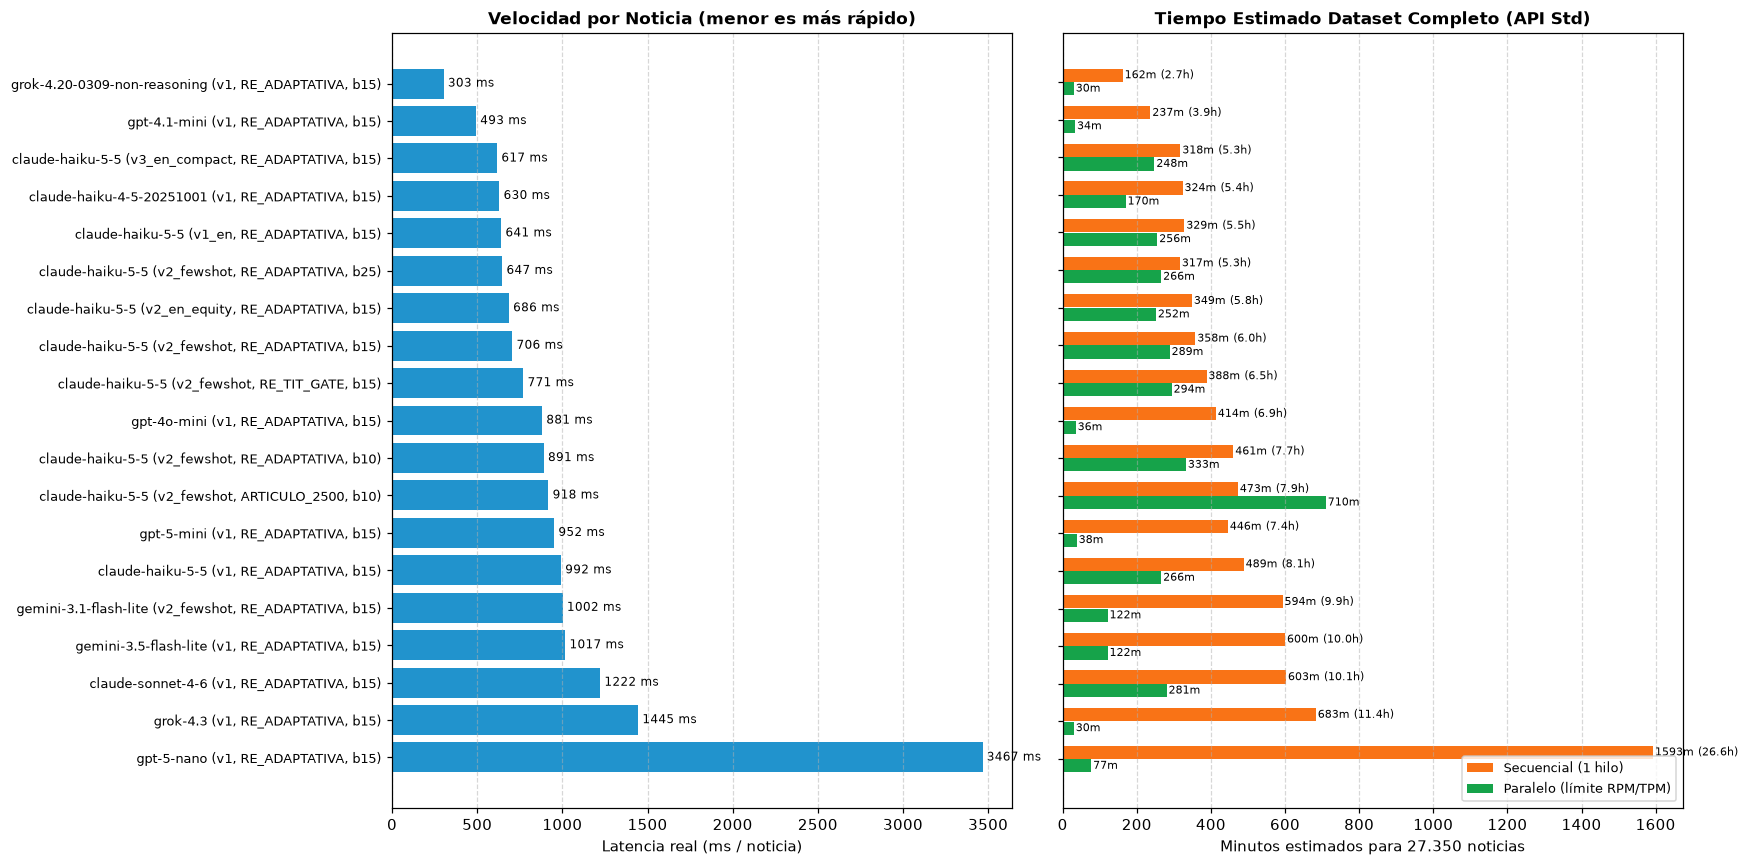

In [34]:
N_PROD = 27_350
df_t_cache = _load_cache_df()
df_t_ok = df_t_cache[(df_t_cache["motivo"] != "error") & df_t_cache["lat_ms"].notna()].copy()

filas_tiempo = []
for exp_id, grp in df_t_ok.groupby("exp_id"):
    partes = str(exp_id).split("|")
    if len(partes) != 4 or partes[2] == "MT_TEST":
        continue
    m_nom, p_key, ctx_k, b_tag = partes
    b_val = int(b_tag.lstrip("b")) if b_tag.startswith("b") and b_tag[1:].isdigit() else 15
    if len(grp) < 60:
        continue

    lat_doc_ms = float(grp["lat_ms"].mean())
    s_por_lote = (lat_doc_ms * b_val) / 1000.0
    in_t = float(grp["in_tokens"].mean()) if grp["in_tokens"].notna().any() else 200.0
    out_t = float(grp["out_tokens"].mean()) if grp["out_tokens"].notna().any() else 90.0

    info = CATALOGO_MODELOS.get(m_nom, {"rpm": 30, "tpm": 100_000, "pause_s": 1.0, "rpd": 0})
    n_lotes_27k = int(np.ceil(N_PROD / b_val))

    # Escenario A: 1 hilo secuencial respetando pause_s del catálogo
    min_secuencial = (n_lotes_27k * (s_por_lote + info["pause_s"])) / 60.0
    # Escenario B: concurrencia asíncrona limitada por el cuello de botella real (RPM, TPM o latencia de red)
    min_por_rpm = n_lotes_27k / max(info["rpm"], 1)
    min_por_tpm = (N_PROD * (in_t + out_t)) / max(info["tpm"], 1)
    min_optimo = max(min_por_rpm, min_por_tpm)

    acc_val = np.nan
    if len(grp) == len(df_silver):
        acc_val = calcular_kpis(y_true, df_silver[["ticker", "title"]].merge(grp, left_on=["ticker", "title"], right_on=["ticker", "titular"], how="left").fillna({"motivo": "error", "label": 0}), exp_id)["Accuracy"]

    filas_tiempo.append({
        "Experimento": f"{m_nom} ({p_key}, {ctx_k}, b{b_val})",
        "N": len(grp),
        "Accuracy": acc_val,
        "ms/doc": round(lat_doc_ms, 0),
        "s/lote": round(s_por_lote, 2),
        "Lotes 27k": n_lotes_27k,
        "27k Secuencial (min)": round(min_secuencial, 1),
        "27k Secuencial (h)": round(min_secuencial / 60.0, 2),
        "27k Paralelo RPM/TPM (min)": round(min_optimo, 1),
    })

df_tiempos = pd.DataFrame(filas_tiempo).sort_values("ms/doc", ascending=True)
display(df_tiempos)

if not df_tiempos.empty:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, max(4.5, 0.42 * len(df_tiempos))), dpi=110)
    y_p = np.arange(len(df_tiempos))
    ax1.barh(y_p, df_tiempos["ms/doc"], color="#0284c7", alpha=0.88)
    ax1.set_yticks(y_p)
    ax1.set_yticklabels(df_tiempos["Experimento"], fontsize=8.5)
    ax1.invert_yaxis()
    ax1.set_xlabel("Latencia real (ms / noticia)")
    ax1.set_title("Velocidad por Noticia (menor es más rápido)", fontsize=11, fontweight="bold")
    ax1.grid(axis="x", linestyle="--", alpha=0.5)
    for i, v in enumerate(df_tiempos["ms/doc"]):
        ax1.text(v + 25, i, f"{v:.0f} ms", va="center", fontsize=8)

    ax2.barh(y_p - 0.18, df_tiempos["27k Secuencial (min)"], 0.35, label="Secuencial (1 hilo)", color="#f97316")
    ax2.barh(y_p + 0.18, df_tiempos["27k Paralelo RPM/TPM (min)"], 0.35, label="Paralelo (límite RPM/TPM)", color="#16a34a")
    ax2.set_yticks(y_p)
    ax2.set_yticklabels([""] * len(df_tiempos))
    ax2.invert_yaxis()
    ax2.set_xlabel("Minutos estimados para 27.350 noticias")
    ax2.set_title("Tiempo Estimado Dataset Completo (API Std)", fontsize=11, fontweight="bold")
    ax2.legend(loc="lower right", fontsize=8.5)
    ax2.grid(axis="x", linestyle="--", alpha=0.5)
    for i, (vs, vp) in enumerate(zip(df_tiempos["27k Secuencial (min)"], df_tiempos["27k Paralelo RPM/TPM (min)"])):
        ax2.text(vs + 5, i - 0.18, f"{vs:.0f}m ({vs/60:.1f}h)", va="center", fontsize=7.5)
        ax2.text(vp + 5, i + 0.18, f"{vp:.0f}m", va="center", fontsize=7.5)

    plt.tight_layout()
    plt.show()

## Resumen ejecutivo y comparativa al completo de los resultados obtenidos en estas pruebas

=== TABLA MAESTRA COMPLETA (16 configuraciones con N=150) ===
CAMPEÓN GLOBAL: claude-haiku-5-5 (v1_en) [Anthropic] -> Acc=89.3% | F1=0.892 | Inv=1 | Coste Batch 27.350=$1.52 | Seq=5.48h / Par=255.6m


,Modelo / Prompt,Proveedor,Acc (%),F1,F2,Rec+1,Rec0,Rec-1,Inv,In+Out tok,ms/doc,27k Seq (h),27k Par (min),Free Tier,Coste Std ($),Coste Batch ($)
0,claude-haiku-5-5 (v1_en),Anthropic,89.3,0.892,0.893,0.848,0.910,0.923,1,307+160,641.0,5.48,255.6,Solo pago,3.03,1.52
1,claude-haiku-5-5 (v1),Anthropic,89.3,0.892,0.895,0.870,0.897,0.923,2,315+171,992.0,8.15,266.2,Solo pago,3.21,1.60
2,grok-4.3 (v1),Xai,86.7,0.859,0.864,0.848,0.872,0.885,4,196+62,1445.0,11.39,30.4,Solo pago,10.92,5.46
3,claude-haiku-5-5 (v3_en_compact),Anthropic,85.3,0.852,0.864,0.891,0.808,0.923,2,297+156,617.0,5.30,247.8,Solo pago,2.95,1.47
4,claude-haiku-5-5 (v2_fewshot),Anthropic,85.3,0.839,0.821,0.696,0.974,0.769,2,357+172,706.0,5.97,289.1,Solo pago,3.32,1.66
5,gpt-4.1-mini (v1),Openai,84.7,0.847,0.840,0.717,0.910,0.885,0,184+64,493.0,3.95,33.8,Solo pago,4.80,2.40
6,claude-haiku-5-5 (v2_en_equity),Anthropic,84.0,0.840,0.834,0.761,0.885,0.846,2,302+159,686.0,5.82,252.1,Solo pago,3.00,1.50
7,gemini-3.5-flash-lite (v1),Gemini,84.0,0.834,0.828,0.848,0.859,0.769,3,179+92,1017.0,10.01,121.6,3.6 d,7.75,3.88
8,claude-sonnet-4-6 (v1),Anthropic,84.0,0.834,0.848,0.848,0.808,0.923,1,216+92,1222.0,10.05,280.8,Solo pago,55.58,27.79
9,gpt-5-mini (v1),Openai,82.7,0.820,0.832,0.848,0.795,0.885,4,184+97,952.0,7.44,38.3,Solo pago,6.54,3.27


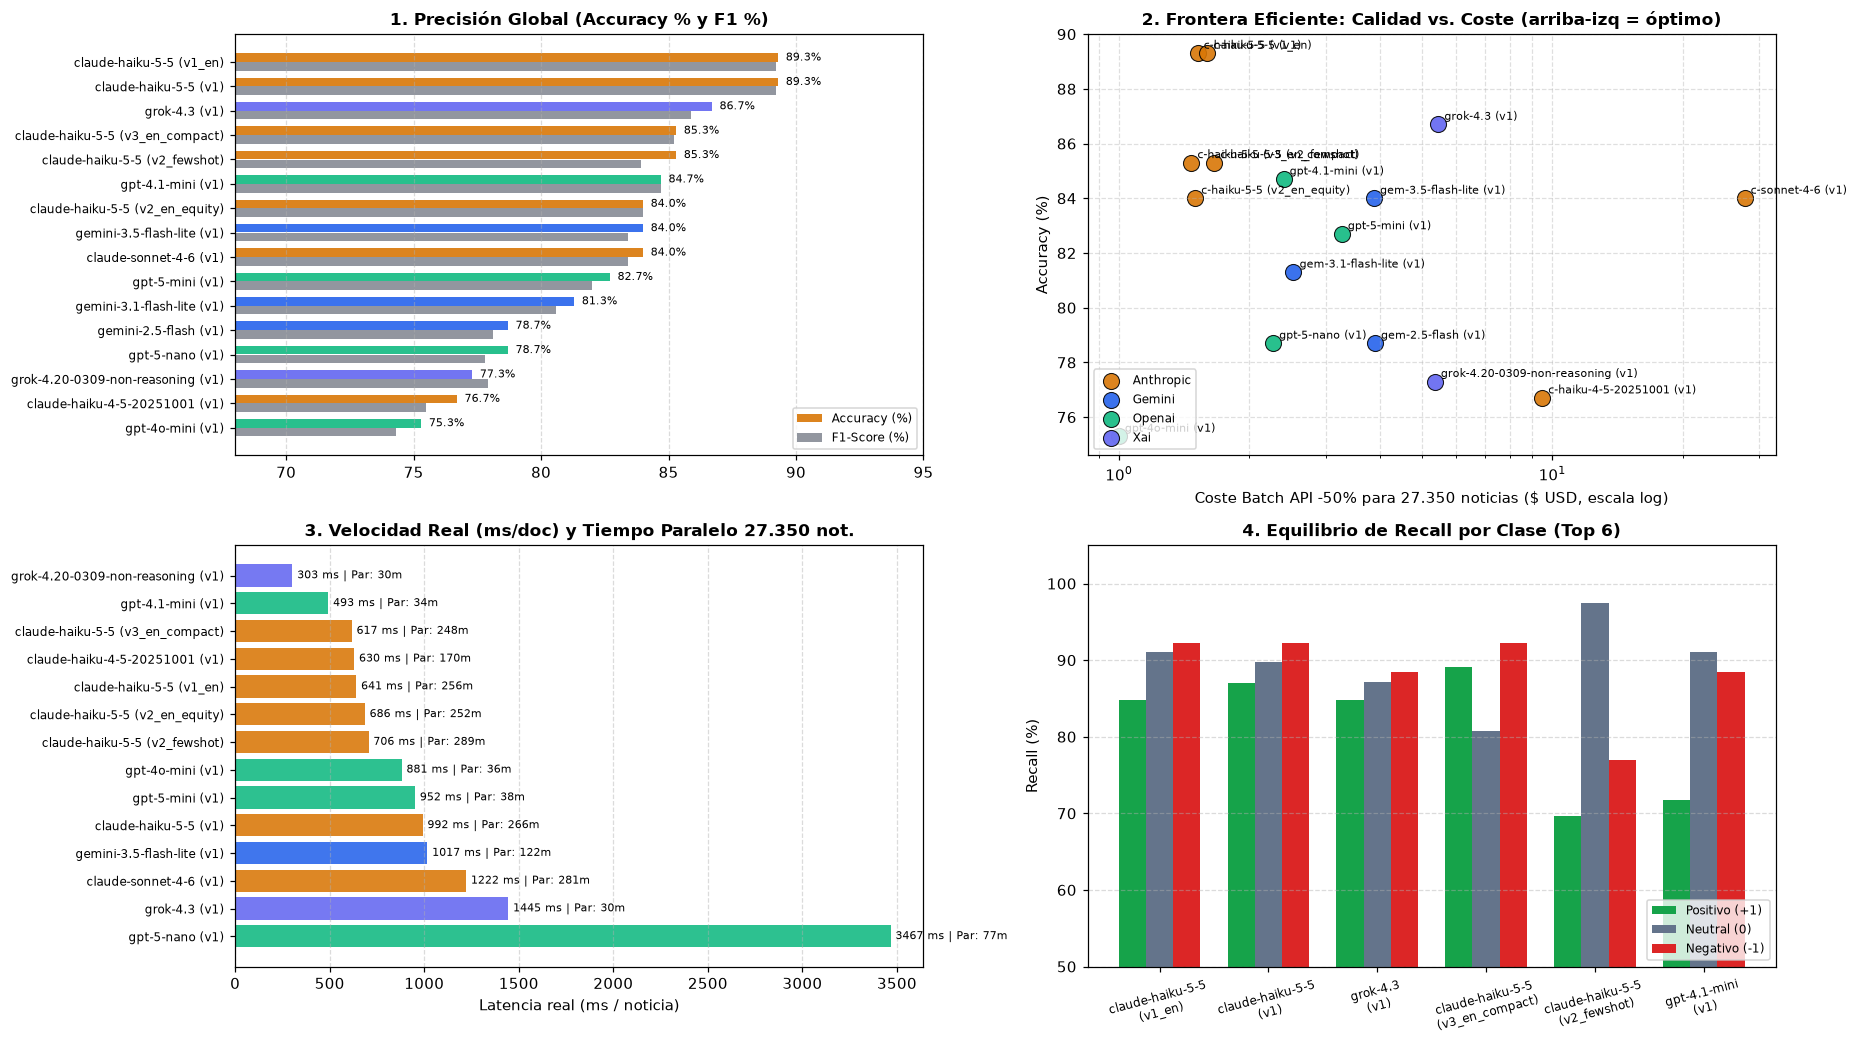

In [37]:
N_PROD = 27_350
df_all_cache = _load_cache_df()
df_ok_all = df_all_cache[df_all_cache["motivo"] != "error"].copy()

filas_maestro = []
for exp_id, grp in df_ok_all.groupby("exp_id"):
    partes = str(exp_id).split("|")
    if len(partes) != 4 or partes[2] == "MT_TEST":
        continue
    m_nom, p_k, ctx_k, b_tag = partes
    b_val = int(b_tag.lstrip("b")) if b_tag.startswith("b") and b_tag[1:].isdigit() else 15
    df_aligned = df_silver[["ticker", "title"]].merge(
        grp.drop_duplicates(subset=["ticker", "titular"]),
        left_on=["ticker", "title"], right_on=["ticker", "titular"], how="left"
    ).fillna({"motivo": "error", "label": 0})
    k = calcular_kpis(y_true, df_aligned, exp_id)
    if k["N"] < len(df_silver):
        continue

    in_t = float(grp["in_tokens"].mean()) if grp["in_tokens"].notna().any() else 200.0
    out_t = float(grp["out_tokens"].mean()) if grp["out_tokens"].notna().any() else 90.0
    lat_ms = float(grp["lat_ms"].mean()) if grp["lat_ms"].notna().any() else np.nan
    info = CATALOGO_MODELOS.get(m_nom, {"prov": "?", "rpm": 30, "tpm": 100_000, "rpd": 0, "in_usd_1m": 0.0, "out_usd_1m": 0.0, "pause_s": 1.0})

    n_lotes = int(np.ceil(N_PROD / b_val))
    usd_std = ((N_PROD * in_t) / 1e6) * info["in_usd_1m"] + ((N_PROD * out_t) / 1e6) * info["out_usd_1m"]
    min_seq = (n_lotes * (((lat_ms * b_val) / 1000.0) + info["pause_s"])) / 60.0 if pd.notna(lat_ms) else np.nan
    min_par = max(n_lotes / max(info["rpm"], 1), (N_PROD * (in_t + out_t)) / max(info["tpm"], 1))
    dias_ft = f"{n_lotes / info['rpd']:.1f} d" if info["rpd"] > 0 else "Solo pago"

    filas_maestro.append({
        "Modelo / Prompt": f"{m_nom} ({p_k})",
        "Proveedor": info["prov"].capitalize(),
        "Acc (%)": round(k["Accuracy"] * 100, 1),
        "F1": k["F1-Score"],
        "F2": k["F2(β=2)"],
        "Rec+1": k["Rec+1"],
        "Rec0": k["Rec0"],
        "Rec-1": k["Rec-1"],
        "Inv": k["Inv"],
        "In+Out tok": f"{in_t:.0f}+{out_t:.0f}",
        "ms/doc": round(lat_ms, 0) if pd.notna(lat_ms) else np.nan,
        "27k Seq (h)": round(min_seq / 60.0, 2) if pd.notna(min_seq) else np.nan,
        "27k Par (min)": round(min_par, 1),
        "Free Tier": dias_ft,
        "Coste Std ($)": round(usd_std, 2),
        "Coste Batch ($)": round(usd_std * 0.5, 2),
    })

df_maestro = pd.DataFrame(filas_maestro).sort_values(["Acc (%)", "F1", "Coste Batch ($)"], ascending=[False, False, True]).reset_index(drop=True)
top = df_maestro.iloc[0]
print(f"=== TABLA MAESTRA COMPLETA ({len(df_maestro)} configuraciones con N=150) ===")
print(f"CAMPEÓN GLOBAL: {top['Modelo / Prompt']} [{top['Proveedor']}] -> Acc={top['Acc (%)']}% | F1={top['F1']} | Inv={top['Inv']} | Coste Batch 27.350=${top['Coste Batch ($)']} | Seq={top['27k Seq (h)']}h / Par={top['27k Par (min)']}m")
display(df_maestro)

if not df_maestro.empty:
    fig, axes = plt.subplots(2, 2, figsize=(17, max(9.5, 0.35 * len(df_maestro) + 4)), dpi=110)
    col_prov = {"Anthropic": "#d97706", "Openai": "#10b981", "Xai": "#6366f1", "Gemini": "#2563eb"}
    bar_cols = [col_prov.get(p, "#64748b") for p in df_maestro["Proveedor"]]

    # (0,0) Ranking Accuracy & F1
    ax = axes[0, 0]
    y_i = np.arange(len(df_maestro))
    ax.barh(y_i - 0.18, df_maestro["Acc (%)"], 0.35, color=bar_cols, alpha=0.9, label="Accuracy (%)")
    ax.barh(y_i + 0.18, df_maestro["F1"] * 100, 0.35, color="#0f172a", alpha=0.45, label="F1-Score (%)")
    ax.set_yticks(y_i)
    ax.set_yticklabels(df_maestro["Modelo / Prompt"], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(68, 95)
    ax.set_title("1. Precisión Global (Accuracy % y F1 %)", fontsize=11, fontweight="bold")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(axis="x", linestyle="--", alpha=0.45)
    for i, (a, f) in enumerate(zip(df_maestro["Acc (%)"], df_maestro["F1"] * 100)):
        ax.text(a + 0.3, i - 0.18, f"{a:.1f}%", va="center", fontsize=7.5)

    # (0,1) Frontera Pareto: Calidad vs Coste Batch ($)
    ax = axes[0, 1]
    for prov, grp_p in df_maestro.groupby("Proveedor"):
        ax.scatter(grp_p["Coste Batch ($)"], grp_p["Acc (%)"], s=110, color=col_prov.get(prov, "#64748b"), label=prov, alpha=0.9, edgecolors="black", linewidths=0.7)
    for _, r in df_maestro.iterrows():
        ax.annotate(r["Modelo / Prompt"].replace("claude-", "c-").replace("gemini-", "gem-"), (r["Coste Batch ($)"], r["Acc (%)"]), xytext=(4, 3), textcoords="offset points", fontsize=7.2)
    ax.set_xscale("log")
    ax.set_xlabel("Coste Batch API -50% para 27.350 noticias ($ USD, escala log)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title("2. Frontera Eficiente: Calidad vs. Coste (arriba-izq = óptimo)", fontsize=11, fontweight="bold")
    ax.legend(loc="lower left", fontsize=8)
    ax.grid(True, which="both", linestyle="--", alpha=0.4)

    # (1,0) Velocidad (ms/doc) y Tiempo Paralelo (min)
    ax = axes[1, 0]
    df_t = df_maestro.dropna(subset=["ms/doc"]).sort_values("ms/doc", ascending=True)
    y_t = np.arange(len(df_t))
    ax.barh(y_t, df_t["ms/doc"], color=[col_prov.get(p, "#64748b") for p in df_t["Proveedor"]], alpha=0.88)
    ax.set_yticks(y_t)
    ax.set_yticklabels(df_t["Modelo / Prompt"], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Latencia real (ms / noticia)")
    ax.set_title("3. Velocidad Real (ms/doc) y Tiempo Paralelo 27.350 not.", fontsize=11, fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.45)
    for i, (ms, mp) in enumerate(zip(df_t["ms/doc"], df_t["27k Par (min)"])):
        ax.text(ms + 25, i, f"{ms:.0f} ms | Par: {mp:.0f}m", va="center", fontsize=7.5)

    # (1,1) Equilibrio por clase (Top 6)
    ax = axes[1, 1]
    top6 = df_maestro.head(6)
    x_6 = np.arange(len(top6))
    w = 0.25
    ax.bar(x_6 - w, top6["Rec+1"] * 100, w, label="Positivo (+1)", color="#16a34a")
    ax.bar(x_6,     top6["Rec0"] * 100,  w, label="Neutral (0)",   color="#64748b")
    ax.bar(x_6 + w, top6["Rec-1"] * 100, w, label="Negativo (-1)", color="#dc2626")
    ax.set_xticks(x_6)
    ax.set_xticklabels([s.replace(" (", "\n(") for s in top6["Modelo / Prompt"]], fontsize=7.8, rotation=15)
    ax.set_ylim(50, 105)
    ax.set_ylabel("Recall (%)")
    ax.set_title("4. Equilibrio de Recall por Clase (Top 6)", fontsize=11, fontweight="bold")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(axis="y", linestyle="--", alpha=0.45)

    plt.tight_layout()
    plt.show()